<a href="https://colab.research.google.com/github/aryan7889/MachineLearning/blob/main/november_1_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data = pd.DataFrame({
    "Age": [20, 22, 25, 27, 30, 35, 40, 45],
    "Salary": [20000, 25000, 30000, 40000, 50000, 70000, 90000, 120000]
})

print(data)

   Age  Salary
0   20   20000
1   22   25000
2   25   30000
3   27   40000
4   30   50000
5   35   70000
6   40   90000
7   45  120000


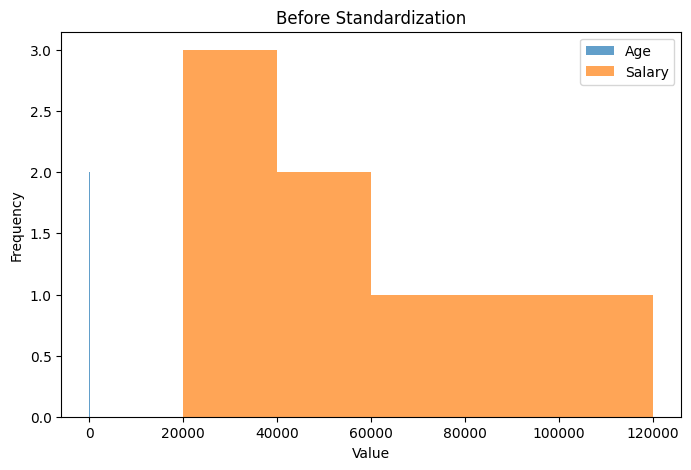

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(data["Age"], bins=5, alpha=0.7, label="Age")
plt.hist(data["Salary"], bins=5, alpha=0.7, label="Salary")

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Before Standardization")
plt.legend()

plt.show()

/tmp/ipykernel_1173/1888241683.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


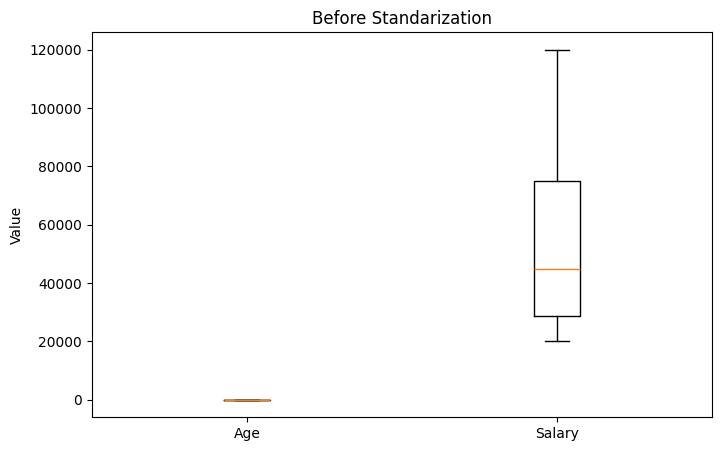

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot(
    [data["Age"],data["Salary"]],
    labels = ["Age", "Salary"]
)
plt.title("Before Standarization")
plt.ylabel("Value")
plt.show()

#we use the box plot to actually see thedifference between the value in the column
#like the mx then the medina then the lowest value in the column


In [ ]:
age_mean = data["Age"].mean()
age_std = data["Age"].std()

data["Age_Z"] = (data["Age"] - age_mean)/age_std

In [ ]:
print(data)

   Age  Salary     Age_Z
0   20   20000 -1.188891
1   22   25000 -0.962435
2   25   30000 -0.622752
3   27   40000 -0.396297
4   30   50000 -0.056614
5   35   70000  0.509525
6   40   90000  1.075663
7   45  120000  1.641802


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()

In [ ]:
data_scalerd = scaler.fit_transform(data[["Age","Salary"]])
print(data_scalerd)
#fit calculate the mean and the sd of the column and transform help
#to calcylate the z score value and to create a object of it.

[[-1.27097782 -1.08204012]
 [-1.02888681 -0.93017484]
 [-0.66575029 -0.77830956]
 [-0.42365927 -0.474579  ]
 [-0.06052275 -0.17084844]
 [ 0.54470478  0.43661268]
 [ 1.14993231  1.0440738 ]
 [ 1.75515984  1.95526547]]


In [ ]:
scaled_data = pd.DataFrame(
    data_scalerd,
    columns = ["Age","Salary"]
)

print(scaled_data)

        Age    Salary
0 -1.270978 -1.082040
1 -1.028887 -0.930175
2 -0.665750 -0.778310
3 -0.423659 -0.474579
4 -0.060523 -0.170848
5  0.544705  0.436613
6  1.149932  1.044074
7  1.755160  1.955265


In [ ]:
print(data[["Age","Salary"]].mean())
print(data[["Age","Salary"]].std())

Age          30.5
Salary    55625.0
dtype: float64
Age           8.831761
Salary    35197.148829
dtype: float64


In [ ]:
print(scaled_data.mean())
print(scaled_data.std())


#So here is the observation that we can see after the standardization mean is varying,
# mean is converted to zero and the standard deviation is approximately to one that means the
#values are centralized around the origin which gives mean is equal to zero.

Age       0.0
Salary    0.0
dtype: float64
Age       1.069045
Salary    1.069045
dtype: float64


In [ ]:
#We can't presume that after standardization all values will be between minus 1 and plus 1.
#That assumption is wrong. Standardization does not force values into the fixed range.
#The values can be in any range, but the property is mean is equal to 0 and
#standard deviation is approximately equal to 1.




/tmp/ipykernel_1173/153132281.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


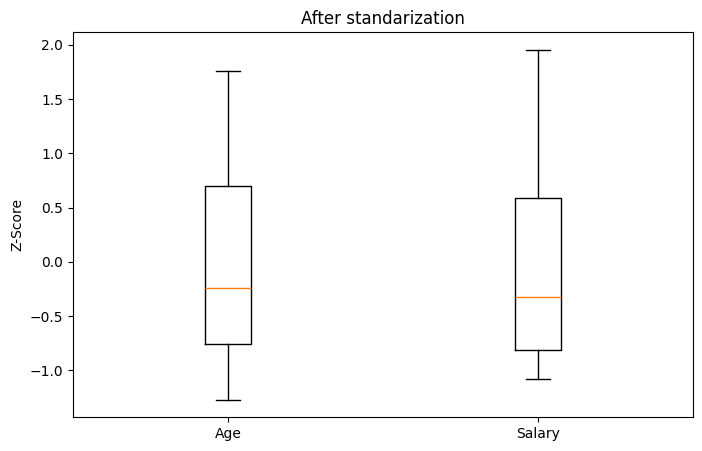

In [ ]:
plt.figure(figsize=(8,5))
plt.boxplot(
    [scaled_data["Age"],scaled_data["Salary"]],
    labels=["Age","Salary"]
)

plt.title("After standarization")
plt.ylabel("Z-Score")

plt.show()

In [ ]:
#One more thing we need to keep in mind that after standardization we didn't change the ordering. We just changed the standard of value. I would select the values at 20, 30, 40, 50. The orders remain the same. Just the scale of values comes to down.
#20 < 30 < 40 < 50    #-1.34 < -0.45 < 0.45 < 1.34

In [ ]:
#now comes the oulier which can make teh mean and the sd change so now the time is to learn the robust

In [ ]:
#Before giving the data to an ML model, we prepare it. We prepare it in terms of missing values, duplicate records, different numerical scales, categorical values, outliers and incorrect data types. This is what comes under pre-processing. Think of it like preparing ingredients before comes to the part of cooking.

In [ ]:
from sklearn.model_selection import train_test_split

X = data[["Age","Salary"]]

X_train,X_test = train_test_split(
    X,
    test_size=0.25,
    random_state=42
)

In [ ]:
scaler = StandardScaler()

scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("training data after scaling")
print(X_train_scaled)


print("testing data after scaling")
print(X_test_scaled)


training data after scaling
[[-1.28822335 -1.08543711]
 [ 1.59585878  1.74613796]
 [-0.71140693 -0.8022796 ]
 [-0.1345905  -0.23596459]
 [-0.48068036 -0.5191221 ]
 [ 1.01904235  0.89666544]]
testing data after scaling
[[-1.05749678 -0.94385836]
 [ 0.44222593  0.33035042]]


#Normalization

In [ ]:
import pandas as pd

data = pd.DataFrame({
    "Age": [20, 22, 25, 27, 30, 35, 40, 45],
    "Salary": [20000, 25000, 30000, 40000, 50000, 70000, 90000, 120000]
})

print(data)

   Age  Salary
0   20   20000
1   22   25000
2   25   30000
3   27   40000
4   30   50000
5   35   70000
6   40   90000
7   45  120000


In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

data_normalized = scaler.fit_transform(data)

print(data_normalized)

[[0.   0.  ]
 [0.08 0.05]
 [0.2  0.1 ]
 [0.28 0.2 ]
 [0.4  0.3 ]
 [0.6  0.5 ]
 [0.8  0.7 ]
 [1.   1.  ]]


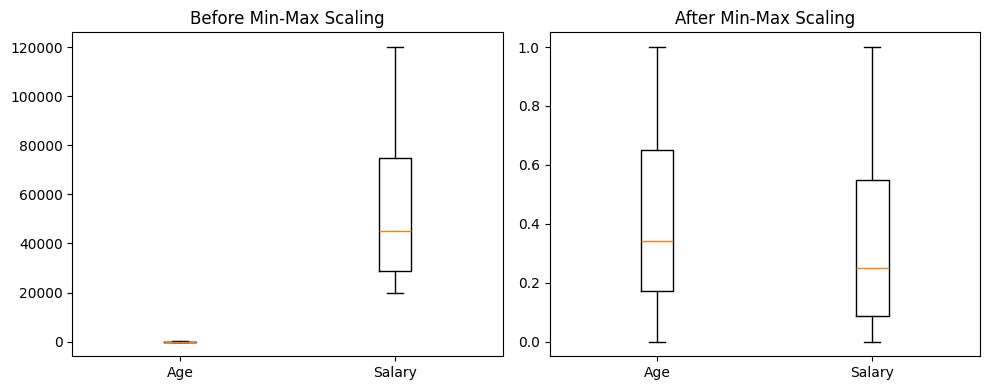

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.boxplot([data["Age"], data["Salary"]])
plt.xticks([1, 2], ["Age", "Salary"])
plt.title("Before Min-Max Scaling")

plt.subplot(1, 2, 2)
plt.boxplot([data_normalized[:, 0], data_normalized[:, 1]])
plt.xticks([1, 2], ["Age", "Salary"])
plt.title("After Min-Max Scaling")

plt.tight_layout()
plt.show()

In [ ]:
salary = [20000, 22000, 25000, 27000, 30000, 35000, 40000, 1000000]

In [ ]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

salary_robust = scaler.fit_transform(salary)

print(salary_robust)

ValueError: Expected 2D array, got 1D array instead:
array=[  20000.   22000.   25000.   27000.   30000.   35000.   40000. 1000000.].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

#LINEAR REGRESSION

In [ ]:
import random
import math

random.seed(42)

TRUE_W = 3.0
TRUE_B = 7.0
N_SAMPLES = 100

X = [random.uniform(0, 10) for _ in range(N_SAMPLES)]
y = [TRUE_W * x + TRUE_B + random.gauss(0, 2.0) for x in X]

print(f"Generated {N_SAMPLES} samples")
print(f"True relationship: y = {TRUE_W}x + {TRUE_B} + (noise)")
print(f"First 5 points: {[(round(X[i], 2), round(y[i], 2)) for i in range(5)]}")

Generated 100 samples
True relationship: y = 3.0x + 7.0 + (noise)
First 5 points: [(6.39, 29.37), (0.25, 7.98), (2.75, 14.22), (2.23, 11.44), (7.36, 28.79)]


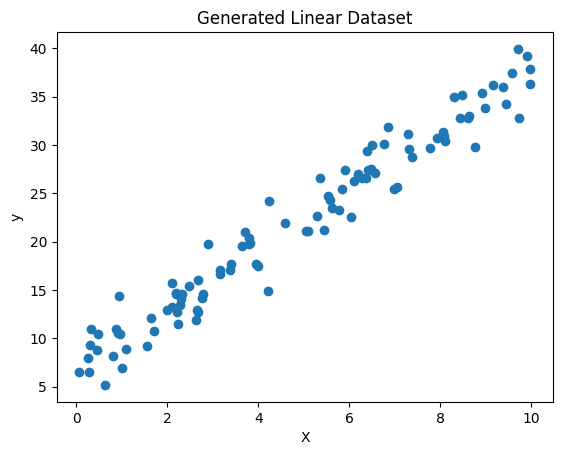

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(X, y)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Generated Linear Dataset")

plt.show()

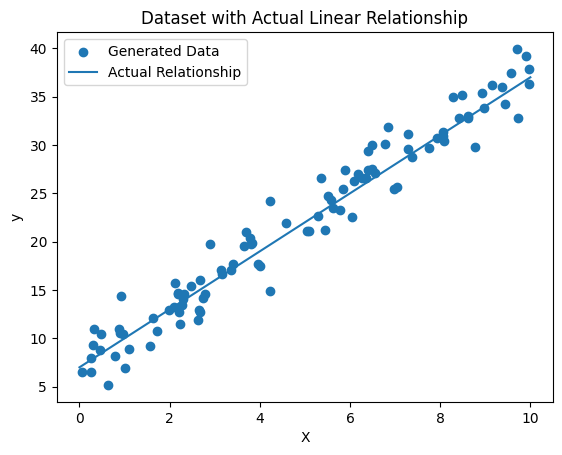

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.scatter(X, y, label="Generated Data")

x_line = np.linspace(0, 10, 100)

y_line = TRUE_W * x_line + TRUE_B

plt.plot(x_line, y_line, label="Actual Relationship")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Dataset with Actual Linear Relationship")

plt.legend()
plt.show()